# QCore Introduction

In this notebook, we will present some of the features of QCore, as well as its submodules for decomposition and SAT synthesis.

## Setup
In order to run the examples in this notebook, you will need to install `qcore` and `qsat` from their respective repositories.

To install qSAT, you will also need `eigen3`. On Ubuntu, it can be installed via `apt install libeigen3-dev`.

In [1]:
pip install cmake ninja setuptools setuptools_scm
    
pip install git+https://github.com/qc-agra-cps/qcore
pip install git+https://github.com/qc-agra-cps/qSAT
    
pip install qiskit qiskit-qasm3-import matplotlib pylatexenc wcwidth

## The Quantum Circuit Model

Within QCore, we use `qcore.QCircuit()` to represent a quantum circuit. 
It supports importing and exporting using both the `OpenQASM 2.0` and the `OpenQASM 3.0` format.

To import a quantum circuit, you can use `circuit.readQCircuit(filename: str)` or `circuit.readQCircuitFromString(string: str)`.
Both methods return an instance of `qcore.FileFormat`, which specifies which format was detected.

To export a circuit, `circuit.toString(format: qcore.FileFormat)` can be used.

In [2]:
from qcore import QCircuit, FileFormat

circuit = QCircuit()
_ = circuit.readQCircuitFromString("""
    OPENQASM 3;
    include "stdgates.inc";
    
    qubit[2] q;
    h q[0];
    cx q[0], q[1];
    """)
circuit.toString(FileFormat.OpenQASM3)

'OPENQASM 3.0;\ninclude "stdgates.inc";\n\nqubit[2] q;\n\nh q[0];\ncx q[0], q[1];'

##### Visualizing Circuits
Quickly visualizing a quantum circuit is possible via the function `qcore.draw_circuit(circuit: qcore.QCircuit)`.

In [3]:
from qcore import draw_circuit

draw_circuit(circuit)

##### Interfacing with Qiskit

QCore can interface with Qiskit, since both support OpenQASM. The function `qcore.circuit_to_qiskit(circuit: qcore.QCircuit)` can be used to easily convert between the two.

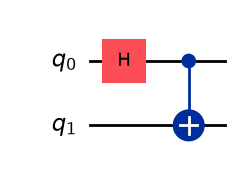

In [4]:
from qcore import circuit_to_qiskit

qiskit_circuit = circuit_to_qiskit(circuit)
qiskit_circuit.draw(output='mpl')

## Creating a simple Toffoli gate:

QCore contains a powerful decomposition library, which is responsible for the efficient decomposition of larger Toffoli gates.
Its main interface is `mcx`, the multi-controlled Toffoli gate:
```python
qcore.decomposition.mcx(
    config:        qcore.decomposition.configuration, 
    controls:      list[int], 
    target:        int, 
    clean_ancilla: list[int], 
    dirty_ancilla: list[int]
    )
```

`qcore.decomposition.configuration` is used to provide information about the optimization target:
- `qcore.decomposition.configuration.ReduceCNotCount` minimizes the number of CNot gates
- `qcore.decomposition.configuration.ReduceTDepth` minimizes the T-Depth

`mcx` can be provided a target and any number of controls and ancilla, and will automatically select the appropriate decomposition for a given configuration.

In [5]:
from qcore import decomposition

config = decomposition.configuration.ReduceCNotCount
circuit = decomposition.mcx(config, [0, 1], 4, [5], [])
draw_circuit(circuit)

##### Decomposing relative phase gates

Within larger algorithms, it might be beneficial to allow the introduction of some relative phase to reduce the cost of the Toffoli operation.
To signify this, `qcore.decomposition.configuration` provides the method `withRelativePhase(is_inverse: bool)`. 

For any circuit composed with `is_inverse=True`, the circuit constructed with `is_inverse=False` will exactly cancel out the introduced phase.

In [6]:
config_cnot = decomposition.configuration.ReduceCNotCount.withRelativePhase(is_inverse=False)
circuit_cnot = decomposition.mcx(config_cnot, [0, 1], 4, [5], [])
print('ReduceCNotCount:')
draw_circuit(circuit_cnot)

config_tdepth = decomposition.configuration.ReduceTDepth.withRelativePhase(is_inverse=False)
circuit_tdepth = decomposition.mcx(config_tdepth, [0, 1], 4, [5], [])
print('ReduceTDepth:')
draw_circuit(circuit_tdepth)

ReduceCNotCount:


ReduceTDepth:


#### Decomposing to basis gates:

To improve the legibility of the circuits, QCore usually inserts *meta-gates* like `RCCX` and `RCCXA` which represent a more complex operation.

To reduce these to the Clifford+T gate set, we provide `qcore.decomposition.resolve_meta_gates(circuit: qcore.QCircuit)`

In [7]:
resolved_cnot = decomposition.resolve_meta_gates(circuit_cnot)
print('ReduceCNotCount:')
draw_circuit(resolved_cnot)

resolved_tdepth = decomposition.resolve_meta_gates(circuit_tdepth)
print('ReduceTDepth:')
draw_circuit(resolved_tdepth)

ReduceCNotCount:


ReduceTDepth:


When exporting to QASM or converting to Qiskit, meta gates are reduced automatically:

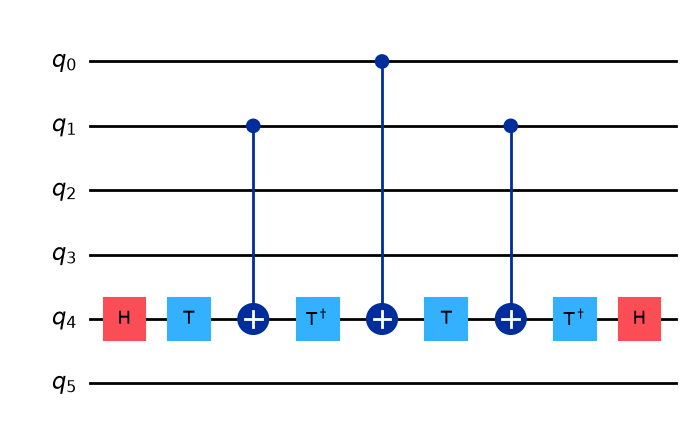

In [8]:
circuit_to_qiskit(circuit_cnot).draw(output='mpl', fold=-1)

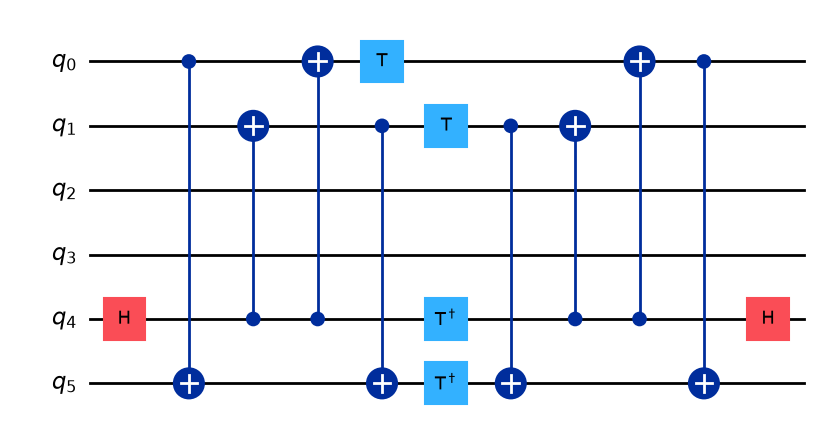

In [9]:
circuit_to_qiskit(circuit_tdepth).draw(output='mpl', fold=-1)

#### Decomposing larger gates

When a larger number of ancilla is provided, `mcx` will use a decomposition over either the dirty or clean ancilla qubits.

##### With one dirty ancilla:

In [10]:
config = decomposition.configuration.ReduceTDepth
larger = decomposition.mcx(config, list(range(3,10)), 0, [], [1])
draw_circuit(larger)

##### With one clean ancilla:

In [11]:
config = decomposition.configuration.ReduceTDepth
larger = decomposition.mcx(config, list(range(3,10)), 0, [1], [])
draw_circuit(larger)

##### With $\frac{n-2}{2}$ clean ancilla:

In [12]:
config = decomposition.configuration.ReduceTDepth
larger = decomposition.mcx(config, list(range(4,12)), 0, [1, 2, 3], [])
draw_circuit(larger)

### Building SAT Circuits

The `qcore.qsat` module provides decomposition of SAT (Satisfiability) problems into quantum circuits.
Here, `qcore.qsat.BooleanFormula` is the model representing the boolean formula in one of two formats:
- Conjunctive Normal Form (CNF)
  Represents a formula as a conjunction of disjunctions of literals: $\bigwedge_{i} \bigvee_{j} x_{i,j}$
- Extended Conjunctive Normal Form (eCNF)
  Represents a formula as a conjunction of exclusive or operations of literals and a conjunction of literals: $\bigwedge_{i} \left(\bigoplus_{j} x_{i,j} \oplus \bigwedge_{k} x_{i,k}\right)$

Similar to `qcore.QCircuit`, `parseFromString(formula: str)` can be used to parse a boolean formula:

In [26]:
from qcore.qsat import BooleanFormula

f = BooleanFormula()
f.parseFromString("p ecnf 4 1\n1 @ 2 3 0\n")

print(f.toString())

# Boolean Formula (ECNF)
# Inputs: 4, Clauses: 1
(x1 * x2 & x3)



Using `qcore.qsat.build_qsat_circuit(formula: qcore.qsat.BooleanFormula, type: qcore.qsat.MiterType)`, Grover Search style quantum circuits can be synthesized from boolean formulas. 

In [27]:
from qcore.qsat import build_qsat_circuit, MiterType
config = decomposition.configuration.ReduceTDepth

circuit = build_qsat_circuit(f, config, MiterType.U_TYPE)
draw_circuit(circuit)

In [15]:
circuit = build_qsat_circuit(f, config, MiterType.V_TYPE)
draw_circuit(circuit)

Additionally, QAOA Ansatz circuits can be built using  `build_qaoa_circuit`:
```python
qcore.qsat.build_qaoa_circuit(
    config: qcore.decomposition.configuration, 
    formula: qcore.qsat.BooleanFormula,
    # Optional
    num_reps: int, 
    num_ancilla: int, 
    max_clause_size: int,
    max_new_variables: int, 
    max_clique_size: int
    )
```

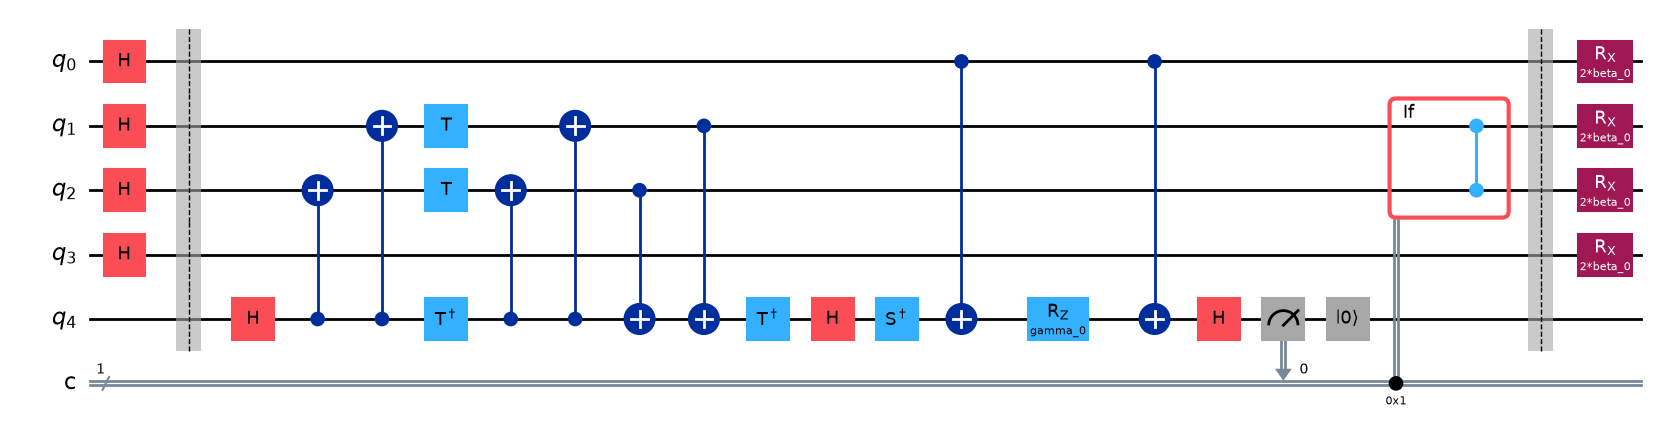

In [16]:
from qcore.qsat import build_qaoa_circuit

config = decomposition.configuration.ReduceTDepth
circuit = build_qaoa_circuit(config, f)
circuit_to_qiskit(circuit).draw(output='mpl', fold=-1)

### eCNF optimization & scheduling

When building QAOA Ansatz circuits, we perform a set of optimization steps to reduce the size of the generated circuits.
Let's consider an example which might appear as part of a larger miter circuit:
\begin{align}
  &(x_1 \oplus x_2 \oplus x_3) \\
  \land &(x_1 \oplus x_2 \oplus x_4) \\
  \land &(x_1 \oplus (x_2 \land x_3 \land x_4 \land x_5 \land x_6 \land x_7 \land x_8 \land x_9))
\end{align}

When decomposing this example as a QAOA Ansatz circuit, the large third clause requires the decomposition one large Toffoli gate, which results in a circuit with high depth: 

T-Depth: 72




In [17]:
from qcore.qsat import _saqc

def t_depth(circuit):
    return circuit_to_qiskit(circuit).depth(lambda op: op.name == 't' or op.name == 'tdg')

f.parseFromString("p ecnf 10 3\n1 @ 2 @ 3 0\n1 @ 2 @ 4 0\n1 @ 2 3 4 5 6 7 8 9 0\n")
circuit = build_qaoa_circuit(config, f, num_ancilla=1, max_new_variables=0)
print('T-Depth: ' + str(t_depth(circuit)))
circuit_to_qiskit(circuit).draw(output='mpl',fold=-1)

However, by introducing some additional qubits, we can reduce the size of the clause by breaking it up.

Typically, these steps are performed internally by the function `build_qaoa_circuit`, but for this demonstration we perform them manually:

In [18]:
optimized = _saqc.reduce(f, max_new_variables=3)
print(optimized.toString())

# Boolean Formula (ECNF)
# Inputs: 13, Clauses: 6
(x1 * x2 * x3)
(x1 * x2 * x4)
(x1 * x2 & x3 & x12)
(!x12 * x4 & x5 & x11)
(!x11 * x6 & x7 & x13)
(!x13 * x8 & x9)



Additionally, we can reduce the depth of the resulting circuits by performing clauses with distinct variables in parallel:

In [19]:
scheduled = _saqc.reorder_clique(optimized, max_clique_size=10, max_clause_size=10)
print(scheduled.toString())

# Boolean Formula (ECNF)
# Inputs: 13, Clauses: 6
(!x12 * x4 & x5 & x11)
(!x13 * x8 & x9)
(x1 * x2 * x3)
(!x11 * x6 & x7 & x13)
(x1 * x2 * x4)
(x1 * x2 & x3 & x12)



In [20]:
print('T-Depth (unscheduled): ' +
      str(t_depth(
          _saqc.build_qaoa_ansatz(config, _saqc.assume_ordered(optimized), num_ancilla=1, num_reps=1))))
print('T-Depth (scheduled): ' +
      str(t_depth(
          _saqc.build_qaoa_ansatz(config, scheduled, num_ancilla=1, num_reps=1))))

T-Depth (unscheduled): 28
T-Depth (scheduled): 24


T-Depth: 24




In [21]:
circuit = build_qaoa_circuit(config, optimized, num_ancilla=1, max_new_variables=0)
print('T-Depth: ' +
      str(circuit_to_qiskit(circuit).depth(lambda op: op.name == 't' or op.name == 'tdg')))
circuit_to_qiskit(circuit).draw(output='mpl',fold=-1)

#### Comparing Ancilla use vs. Extra Qubits for clause rewriting:

Here, we experimentally show circuit depth by manually varying the number of qubits designated for rewriting and for decomposition.

In [22]:
from IPython.display import display, Markdown
table = '|V\\A|0|1|2|3|4|\n'
table += '|-|-|-|-|-|-|\n'
for new_vars in range(0,10):
    table += '|' + str(new_vars)
    for num_ancilla in range(0, 5):
        circuit = build_qaoa_circuit(config, f, num_ancilla=num_ancilla, max_new_variables=new_vars)
        table += '|' + str(t_depth(circuit))
    table += '|\n'
display(Markdown(table))

|V\A|0|1|2|3|4|
|-|-|-|-|-|-|
|0|72|72|72|72|72|
|1|64|64|64|64|64|
|2|40|40|32|32|32|
|3|28|24|22|14|14|
|4|28|24|22|14|14|
|5|28|24|22|14|14|
|6|28|24|22|14|14|
|7|28|24|22|14|14|
|8|28|24|22|14|14|
|9|28|24|22|14|14|


## QAOA Simulation example
 We show a simulation of the QAOA ansatz in the context of equivalence checking for classical circuits.
 
 Our problem will be a small miter circuit of the two following designs:
 - $Y = (A \lor B) \lor C$
 - $Y = (A \oplus B) \lor C$


Satisfying assignments:
 (1, 0, 1, 0, 0, 1, 1, 0)
 (1, 0, 1, 1, 0, 1, 1, 0)

Return from COBYLA because the objective function has been evaluated MAXFUN times.
Number of function values = 200   Least value of F = 1.1485960658353778   Constraint violation = 0.0
The corresponding X is:
[0.64495003 0.38867403 1.10778671 0.0430103  0.80967885 0.40473886
 0.84295418 0.83876644]
The constraint value is:
[-0.64495003 -0.38867403 -1.10778671 -0.0430103  -0.80967885 -0.40473886
 -0.84295418 -0.83876644 -5.63823527 -5.89451127 -5.17539859 -6.24017501
 -2.3319138  -2.73685379 -2.29863847 -2.30282621]


Continuous optimization result
------------------------------
Converged: False
Message: Return from COBYLA because the objective function has been evaluated MAXFUN times.


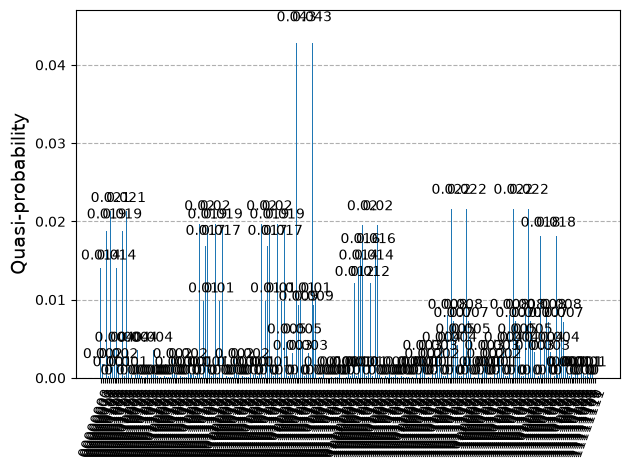

states sorted by probability:
 - 0.04274606150747289: (1, 0, 1, 0, 0, 1, 1, 0)
 - 0.04274606150747289: (1, 0, 1, 1, 0, 1, 1, 0)
 - 0.021627004714839825: (1, 0, 1, 0, 1, 1, 0, 1)
 - 0.021627004714839825: (1, 0, 1, 1, 1, 1, 0, 1)
 - 0.021627004714839807: (1, 0, 1, 0, 1, 0, 1, 1)
 - 0.021627004714839807: (1, 0, 1, 1, 1, 0, 1, 1)
 - 0.02128414529695422: (1, 0, 1, 0, 0, 0, 0, 0)
 - 0.02128414529695422: (1, 0, 1, 1, 0, 0, 0, 0)
 - 0.019627144583365688: (1, 1, 0, 0, 1, 0, 1, 0)
 - 0.019627144583365688: (1, 1, 0, 1, 1, 0, 1, 0)
 - 0.01962714458336568: (1, 1, 0, 0, 1, 1, 0, 0)
 - 0.01962714458336568: (1, 1, 0, 1, 1, 1, 0, 0)
 - 0.019554826832090758: (1, 1, 1, 0, 0, 0, 0, 1)
 - 0.019554826832090758: (1, 1, 1, 1, 0, 0, 0, 1)
 - 0.019252216132820535: (1, 1, 1, 0, 1, 0, 1, 0)
 - 0.019252216132820535: (1, 1, 1, 1, 1, 0, 1, 0)
 - 0.019252216132820528: (1, 1, 1, 0, 1, 1, 0, 0)
 - 0.019252216132820528: (1, 1, 1, 1, 1, 1, 0, 0)
 - 0.018782108884919105: (1, 1, 0, 0, 0, 0, 0, 0)
 - 0.018782108884919105: (

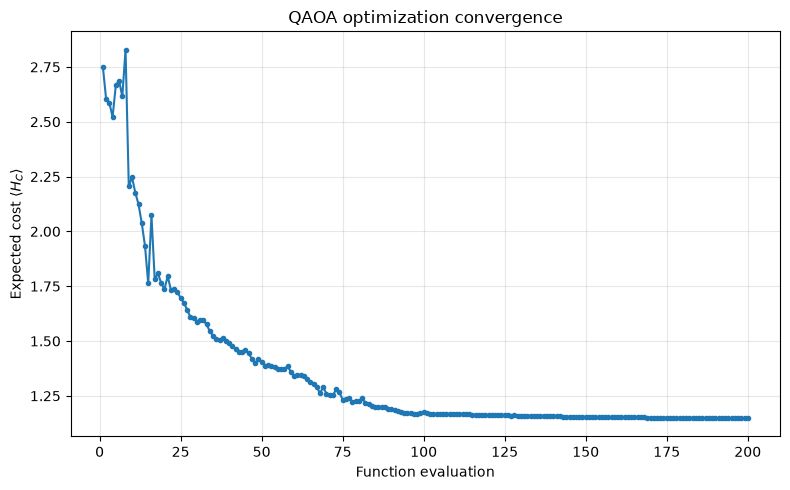

In [23]:
import numpy as np
from scipy.optimize import minimize
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.visualization import plot_histogram

n_reps = 4

f = BooleanFormula()
f.parseFromString("""
p qcnf 8 5
! @ 1 @ 2 @ 3 0
2 @ -8 -5 0
3 @ -6 -7 -8 0
! @ 5 @ 6 @ 7 0
1 0
""")
cost_hamiltonian = SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIZIIZI', 'ZIIIIIZI', 'IIZIIZII', 'IZIIIZII', 'ZIIIIZII', 'IIIIIZZZ', 'ZIIZIIZI', 'IZZIIZII', 'ZIZIIZII', 'ZZIIIZII', 'IZZZIIII', 'ZZZIIZII'],
              coeffs=[ 2.5  +0.j,  0.5  +0.j,  0.25 +0.j,  0.375+0.j, -0.25 +0.j, -0.25 +0.j,
                     -0.125+0.j, -0.125+0.j, -0.125+0.j, -0.5  +0.j, -0.25 +0.j, -0.125+0.j,
                     -0.125+0.j, -0.125+0.j, -0.5  +0.j, -0.125+0.j])
print("""
Satisfying assignments:
 (1, 0, 1, 0, 0, 1, 1, 0)
 (1, 0, 1, 1, 0, 1, 1, 0)
""")

circuit = build_qaoa_circuit(config, f, num_ancilla=0, max_new_variables=0, num_reps=n_reps)
qaoa_circuit = circuit_to_qiskit(circuit)

gamma = list(filter(lambda x: x.name[:5] == 'gamma', qaoa_circuit.parameters))
beta = list(filter(lambda x: x.name[:4] == 'beta', qaoa_circuit.parameters))

initial_parameters = np.array([0.6] * n_reps + [0.5] * n_reps)
optimization_history = []

def energy(parameters: np.ndarray) -> float:
    bound_circuit = qaoa_circuit.assign_parameters(
        { gamma[i]: parameters[i] for i in range(len(gamma)) } 
        | { beta[i]: parameters[i+len(gamma)] for i in range(len(gamma)) },
        inplace=False,
    )
    state = Statevector.from_instruction(bound_circuit)
    energy = np.real(state.expectation_value(cost_hamiltonian))
    optimization_history.append(float(energy))
    return float(energy)

result = minimize(
    energy,
    x0=initial_parameters,
    method="COBYLA",
    bounds=[(0.0, 2 * np.pi)] * n_reps + [(0.0, np.pi)] * n_reps,
    options={
        "maxiter": 200,
        "tol": 1e-8,
        "rhobeg": 0.25,
        "disp": True,
    },
)
optimal_values = result.x

print("\nContinuous optimization result")
print("------------------------------")
print("Converged:", result.success)
print("Message:", result.message)


optimized_circuit = qaoa_circuit.assign_parameters(
    { gamma[i]: optimal_values[i] for i in range(len(gamma)) } 
    | { beta[i]: optimal_values[i+len(gamma)] for i in range(len(gamma)) },
    inplace=False,
)

optimized_state = Statevector.from_instruction(optimized_circuit)
probabilities = optimized_state.probabilities()
display(plot_histogram(optimized_state.probabilities_dict()))
keys = []
for basis_index, probability in enumerate(probabilities):
    assignment = tuple(
        (basis_index >> (qubit)) & 1
        for qubit in range(qaoa_circuit.num_qubits)
    )
    keys.append({
            "assignment": assignment,
            "probability": float(probability),
        })
keys.sort(key=lambda item: ( -item["probability"] ))

print(f'states sorted by probability:')
for i in keys[:100]:
    print(f' - {i["probability"]}: {i["assignment"]}')

import matplotlib.pyplot as plt
history = np.asarray(optimization_history, dtype=float)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(history) + 1),
    history, marker="o", markersize=3, linewidth=1.5)

plt.xlabel("Function evaluation")
plt.ylabel(r"Expected cost $\langle H_C\rangle$")
plt.title("QAOA optimization convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()